# 🍕 Food Image Classification (Food-101): CNN vs EfficientNet vs CLIP

**ML project:** recognise the type of dish from a photo: the 101 dishes of Food-101 **plus 16 Khmer dishes**
(lok lak, num banh chok, samlor korko, prahok ktiss, …) = 117 dishes. The best model is then used by the
**Klean Nham food search app** (`food_search.ipynb`): upload a photo → the app names the dish, shows how to cook it
(`data/recipes.csv`) and lists places in Phnom Penh that serve it.
When a guess is wrong, the user's correction is remembered at once and used for the next training
(section 9).

| # | Model | Idea | Training |
|---|---|---|---|
| 1 | **Small CNN** (from scratch) | baseline: what a network learns with no prior knowledge | all layers, random start |
| 2 | **EfficientNet-B0** (transfer learning) | reuse features learned on ImageNet (1.28M photos) | new head first, then fine-tune everything |
| 3 | **CLIP ViT-B/32** (zero-shot) | match the photo to the *text* "a photo of pizza" | **no training at all** |

**Datasets:** (1) [Food-101](https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/) (Bossard et al., 2014; on Kaggle as
*kmader/food41*): 101 dishes × 1,000 photos = 101,000 photos. Official split: 750 train + 250 test photos per dish.
The *training* photos were deliberately left a little noisy (some wrong labels, odd colours); the *test* photos were
checked by hand.
(2) **Khmer dishes** from two Roboflow Universe datasets (CC BY 4.0): [khfood](https://universe.roboflow.com/dataset-poorm/khfood-rjsdk) and [kh-food image](https://universe.roboflow.com/khfood-image-g3hpx/kh-food-image), merged by `scrapers/khfood_build.py` into 16 dishes, 932 unique photos (699 train / 233 test, ~45 per dish for training).

**Where to run it**

| Where | How | Time (full run) |
|---|---|---|
| **Kaggle** (recommended) | New notebook → *File → Import notebook* → this file. *Add Input* → search **food41** (kmader). Settings: **Accelerator GPU T4**, **Internet on**. *Run all*. | ~1.5–2 h |
| **Google Colab** | Upload this notebook, *Runtime → Change runtime type → T4 GPU*, *Run all* (downloads Food-101, 5 GB) | ~2 h |
| **This Mac** (M3 Pro) | Kernel *venv (food-search)*. Set `FOOD101_DIR` to an unzipped Food-101 (or let it download, ~10 GB disk). On the Apple GPU it uses **all photos with fewer epochs** (see Settings). | ~2 h |

**What you get:** `models/food101_efficientnet_b0.pt` + `models/food101_classes.json` (used by the app) and
`results/food_classification/` (tables and figures for the report). On Kaggle/Colab, download
`food_classification_outputs.zip` at the end and unzip it into the project folder.

## 0. Setup

In [ ]:
# Where are we running? Kaggle and Colab give a free NVIDIA GPU; a Mac works for a quick run.
import os, sys, json, time, random, copy, shutil, platform, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = Path("/kaggle/working").exists()
if IN_KAGGLE:
    ROOT = Path("/kaggle/working")
elif IN_COLAB:
    ROOT = Path("/content")
else:
    ROOT = Path.cwd()          # VS Code starts the kernel in the notebook's folder (the project root)
print("Kaggle:", IN_KAGGLE, "| Colab:", IN_COLAB, "| root:", ROOT)

if IN_COLAB or IN_KAGGLE:      # torch, torchvision, sklearn are preinstalled there; CLIP is not
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch"], check=False)

Kaggle: False | Colab: False | root: /Users/luchtithvichea/Desktop/food-search


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from PIL import Image
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split


def pick_device() -> str:
    # Prefer an NVIDIA GPU, then Apple Silicon (MPS), then CPU.
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


DEVICE = pick_device()
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE,
      f"({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "")

MODELS_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results" / "food_classification"
for folder in (MODELS_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Chart style (same as food_search.ipynb): recessive grid/axes, fixed colour per model
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "figure.dpi": 110})

torch 2.15.0 | torchvision 0.29.2 | device: mps 


### Settings

* **NVIDIA GPU (Kaggle / Colab):** all 101,000 photos, 15 epochs for the CNN and 2 + 6 for EfficientNet.
* **Apple GPU (this Mac) or CPU:** all photos too, but fewer epochs (CNN 10, EfficientNet 1 + 5), because one
  EfficientNet epoch takes ~12 minutes there instead of ~3. Write in the report which one you ran.
* `FOOD_QUICK_RUN=1`: 150 training and 50 test photos per dish, a short check that everything works (not for the report).

In [ ]:
QUICK_RUN = os.environ.get("FOOD_QUICK_RUN") == "1"     # a short check, not for the report
SMOKE_TEST = os.environ.get("FOOD_SMOKE_TEST") == "1"   # tiny run that only checks the code works

CONFIG = dict(
    val_fraction=0.10,            # 10% of the training photos are kept aside to pick the best epoch
    train_per_class=None,         # None = all 750 photos per dish
    test_per_class=None,          # None = all 250
    batch_size=64,
    num_workers=0 if platform.system() == "Darwin" else min(4, os.cpu_count() or 1),
    label_smoothing=0.1, weight_decay=1e-4,
    cnn_img=128, cnn_epochs=15, cnn_lr=3e-3,                       # model 1
    eff_img=224, eff_head_epochs=2, eff_head_lr=1e-3,              # model 2, step 1: new head only
    eff_finetune_epochs=6, eff_lr=3e-4,                            # model 2, step 2: all layers
    use_khmer=True,               # add the 16 Khmer dishes (data/khfood/combined)
    khmer_repeat=8,               # each Khmer training photo is used 8× per epoch (45 vs 675 photos per dish)
    use_feedback=True,            # add the photos app users corrected (data/feedback, section 9)
    feedback_repeat=4,            # each corrected photo is used 4× per epoch
)
RUN_KIND = "full run, NVIDIA GPU"
if DEVICE != "cuda":              # Apple GPU / CPU: every photo, fewer epochs (~2 h on an M3 Pro)
    CONFIG.update(cnn_epochs=10, eff_head_epochs=1, eff_finetune_epochs=5)
    RUN_KIND = f"full data, fewer epochs ({DEVICE})"
if QUICK_RUN:
    CONFIG.update(train_per_class=150, test_per_class=50, cnn_epochs=8, eff_head_epochs=1, eff_finetune_epochs=3)
    RUN_KIND = "quick run (150 photos per dish)"
if SMOKE_TEST:
    CONFIG.update(train_per_class=10, test_per_class=3, batch_size=8, cnn_img=64, eff_img=64,
                  cnn_epochs=1, eff_head_epochs=1, eff_finetune_epochs=1, khmer_repeat=1)
print(RUN_KIND, json.dumps(CONFIG, indent=1))

full data, fewer epochs (mps) {
 "val_fraction": 0.1,
 "train_per_class": null,
 "test_per_class": null,
 "batch_size": 64,
 "num_workers": 0,
 "label_smoothing": 0.1,
 "weight_decay": 0.0001,
 "cnn_img": 128,
 "cnn_epochs": 10,
 "cnn_lr": 0.003,
 "eff_img": 224,
 "eff_head_epochs": 1,
 "eff_head_lr": 0.001,
 "eff_finetune_epochs": 5,
 "eff_lr": 0.0003,
 "use_khmer": true,
 "khmer_repeat": 8,
 "use_feedback": true,
 "feedback_repeat": 4
}


## 1. Data

**Food-101** is looked for in this order: `FOOD101_DIR` (environment variable), Kaggle input (`food41`), `data/food101/`.
If it is not found, the official archive (5 GB) is downloaded with `torchvision`.

**Khmer dishes** (`use_khmer`): `FOOD_KHMER_DIR`, Kaggle input, `data/khfood/combined/` (built by `scrapers/khfood_build.py`).
They are small (~45 training photos per dish against 675 for Food-101), so each Khmer training photo is shown
`khmer_repeat` times per epoch (*oversampling*), with a different random augmentation each time. The test photos are
never repeated, and the results are reported for Food-101 and the Khmer dishes separately.

In [ ]:
def find_food101(bases, khmer=False):
    # Return (images_dir, meta_dir) of a dataset in the Food-101 layout: meta/ has classes.txt, train.txt, test.txt.
    # khmer=False: Food-101 itself; khmer=True: the Khmer dishes (their ids start with "kh_").
    for base in bases:
        base = Path(base)
        if not base.exists():
            continue
        for classes_txt in base.rglob("classes.txt"):
            meta = classes_txt.parent
            if not ((meta / "train.txt").exists() and (meta / "test.txt").exists()):
                continue
            if classes_txt.read_text().startswith("kh_") != khmer:
                continue
            for up in (meta.parent, meta.parent.parent):      # official: food-101/meta; Kaggle food41: meta/meta
                if (up / "images").is_dir():
                    return up / "images", meta
    return None, None


DOWNLOAD_DIR = Path(os.environ.get("FOOD101_DIR") or ROOT / "data" / "food101")
IMAGES_DIR, META_DIR = find_food101([DOWNLOAD_DIR, "/kaggle/input"])

if IMAGES_DIR is None:
    free_gb = shutil.disk_usage(ROOT).free / 1e9
    print(f"Food-101 not found: downloading to {DOWNLOAD_DIR} (5 GB download, 10 GB while unpacking; {free_gb:.0f} GB free)")
    if free_gb < 11:
        raise SystemExit("Not enough free disk space. Free up space, or run this notebook on Kaggle/Colab.")
    DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
    torchvision.datasets.Food101(root=DOWNLOAD_DIR, split="train", download=True)
    (DOWNLOAD_DIR / "food-101.tar.gz").unlink(missing_ok=True)        # keep only the unpacked photos
    IMAGES_DIR, META_DIR = find_food101([DOWNLOAD_DIR])

print("Food-101 images:", IMAGES_DIR)
KH_IMAGES_DIR = KH_META_DIR = None
if CONFIG["use_khmer"]:
    KH_IMAGES_DIR, KH_META_DIR = find_food101([os.environ.get("FOOD_KHMER_DIR") or ROOT / "data" / "khfood" / "combined",
                                               "/kaggle/input"], khmer=True)
    if KH_IMAGES_DIR is None:
        print("⚠️ Khmer dishes not found: training on Food-101 only. Build them with scrapers/khfood_build.py.")
        CONFIG["use_khmer"] = False
print("Khmer images:   ", KH_IMAGES_DIR)

Food-101 images: /Users/luchtithvichea/Desktop/food-search/data/food101/food-101/images
Khmer images:    /Users/luchtithvichea/Desktop/food-search/data/khfood/combined/images


In [ ]:
FOOD101_CLASSES = (META_DIR / "classes.txt").read_text().split()
KHMER_INFO = json.loads((KH_META_DIR / "classes.json").read_text(encoding="utf-8")) if CONFIG["use_khmer"] else []
CLASSES = FOOD101_CLASSES + [k["id"] for k in KHMER_INFO]
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IS_KHMER = np.array([c.startswith("kh_") for c in CLASSES])

NICE_NAMES = {"caesar_salad": "Caesar salad", "creme_brulee": "Crème brûlée", "eggs_benedict": "Eggs Benedict",
              "french_fries": "French fries", "french_onion_soup": "French onion soup", "french_toast": "French toast",
              "greek_salad": "Greek salad", "pho": "Pho", "beef_carpaccio": "Beef carpaccio"}
NICE_NAMES.update({k["id"]: k["name"] for k in KHMER_INFO})


def display_name(c: str) -> str:
    return NICE_NAMES.get(c, c.replace("_", " ").capitalize())


def read_split(meta_dir, images_dir, name: str) -> pd.DataFrame:
    # Lines look like "apple_pie/1005649" -> images/apple_pie/1005649.jpg
    lines = (meta_dir / f"{name}.txt").read_text().split()
    return pd.DataFrame({"path": [str(images_dir / f"{l}.jpg") for l in lines],
                         "label": [CLASS_TO_IDX[l.split("/")[0]] for l in lines]})


def per_class(frame, n):
    if not n:
        return frame.reset_index(drop=True)
    return (frame.sample(frac=1, random_state=SEED).groupby("label", group_keys=False).head(n)
            .sort_values("label").reset_index(drop=True))


def load_split(name):
    parts = [read_split(META_DIR, IMAGES_DIR, name)]
    if CONFIG["use_khmer"]:
        parts.append(read_split(KH_META_DIR, KH_IMAGES_DIR, name))
    return pd.concat(parts, ignore_index=True)


train_full = per_class(load_split("train"), CONFIG["train_per_class"])
test_df = per_class(load_split("test"), CONFIG["test_per_class"])
train_df, val_df = train_test_split(train_full, test_size=CONFIG["val_fraction"], stratify=train_full["label"],
                                    random_state=SEED)
# oversampling: the small Khmer dishes appear khmer_repeat times in the training set (after the validation split,
# so a validation photo is never also a training photo)
khmer_rows = train_df[IS_KHMER[train_df["label"]]]
train_df = pd.concat([train_df] + [khmer_rows] * (CONFIG["khmer_repeat"] - 1), ignore_index=True)
# photos the app's users corrected (section 9): training only, never validation or test. Review them first with
# scrapers/feedback_review.py. (A corrected photo that is also a test photo would make the test score too good.)
FEEDBACK_DIR = ROOT / "data" / "feedback"
feedback_rows = []
if CONFIG["use_feedback"] and (FEEDBACK_DIR / "corrections.jsonl").exists():
    for line in (FEEDBACK_DIR / "corrections.jsonl").read_text(encoding="utf-8").splitlines():
        e = json.loads(line)
        if e.get("dish") in CLASS_TO_IDX and (FEEDBACK_DIR / e["file"]).exists():
            feedback_rows.append({"path": str(FEEDBACK_DIR / e["file"]), "label": CLASS_TO_IDX[e["dish"]]})
if feedback_rows:
    train_df = pd.concat([train_df] + [pd.DataFrame(feedback_rows)] * CONFIG["feedback_repeat"], ignore_index=True)
    print(f"+ {len(feedback_rows)} photos corrected by app users (×{CONFIG['feedback_repeat']})")
train_df, val_df = train_df.sample(frac=1, random_state=SEED).reset_index(drop=True), val_df.reset_index(drop=True)

n_kh = int(IS_KHMER.sum())
print(f"{NUM_CLASSES} dishes ({NUM_CLASSES - n_kh} Food-101 + {n_kh} Khmer) | train {len(train_df):,} "
      f"(Khmer photos ×{CONFIG['khmer_repeat']}) | validation {len(val_df):,} | test {len(test_df):,} "
      f"({int(IS_KHMER[test_df.label].sum())} Khmer)")
if n_kh:
    print("Khmer dishes:", ", ".join(display_name(c) for c in CLASSES if c.startswith("kh_")))

117 dishes (101 Food-101 + 16 Khmer) | train 73,207 (Khmer photos ×8) | validation 7,645 | test 25,483 (233 Khmer)
Khmer dishes: Raw shrimp salad (plea bongkea), Khor (caramelised braised pork), Beef stew (sach ko kho), Stir-fried ginger (cha kney), Salted crab (kdam prai), Khmer curry (kari), Lok lak, Num banh chok, Beef salad (plea sach ko), Prahok ktiss, Samlor korko, Sour soup (samlor machu), Sngao ngam ngov (soup with pickled lime), Vegetable soup (samlor proher), Kanh (minced beef salad), Steamed fish with soy sauce


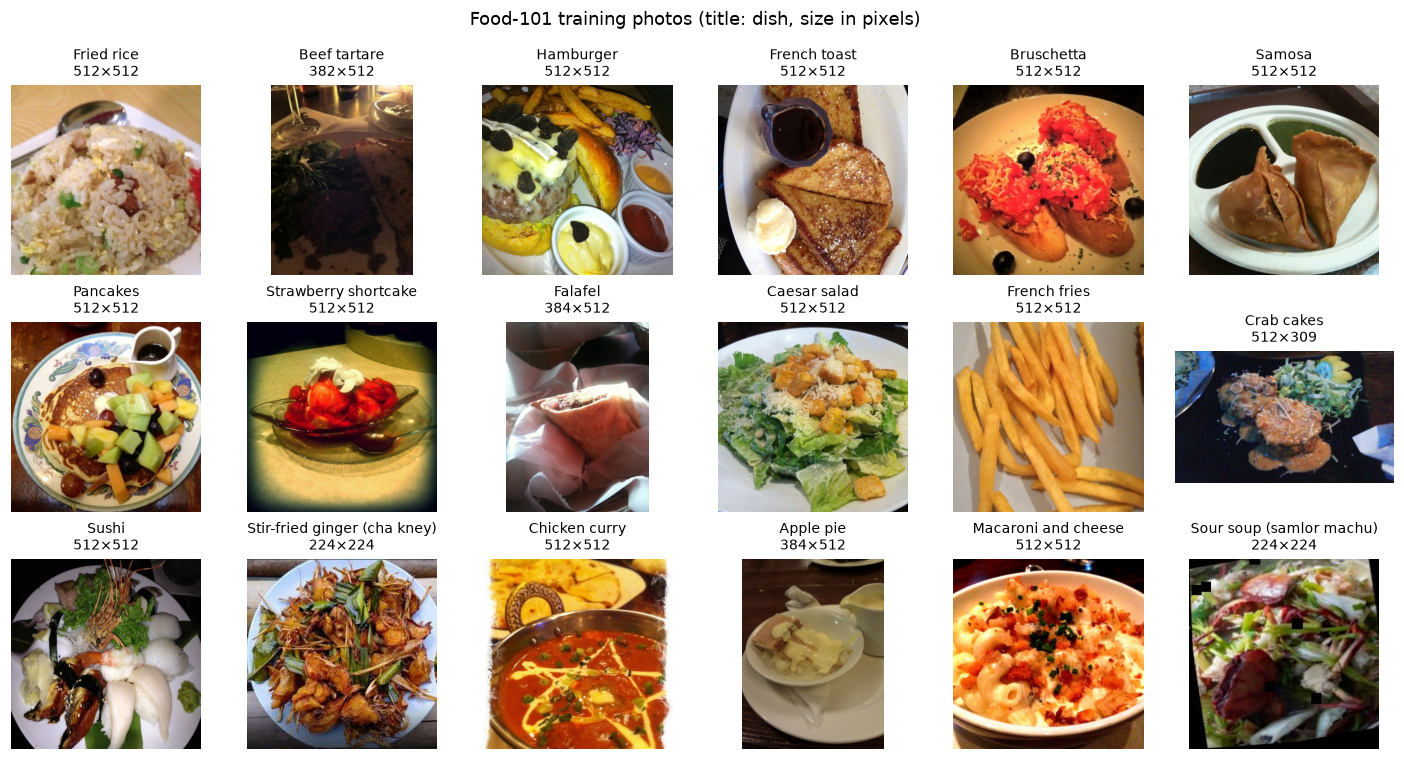

In [6]:
# A look at the data: one random training photo for 18 dishes
picks = train_df.groupby("label").sample(1, random_state=SEED).sample(min(18, NUM_CLASSES), random_state=SEED)
fig, axes = plt.subplots(3, 6, figsize=(13, 7))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, r) in zip(axes.flat, picks.iterrows()):
    img = Image.open(r.path).convert("RGB")
    ax.imshow(img); ax.set_title(f"{display_name(CLASSES[r.label])}\n{img.size[0]}×{img.size[1]}", fontsize=9)
fig.suptitle("Food-101 training photos (title: dish, size in pixels)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "sample_photos.png", bbox_inches="tight"); plt.show()

### From photo to tensor

* **Training:** random crop (35–100% of the photo), random flip, and *TrivialAugment* (one random colour/shape change
  per photo). The network sees a slightly different version of each photo every epoch, which reduces overfitting.
* **Validation / test:** always the same: resize, then a centre crop.
* Pixel values are normalised with the ImageNet mean and standard deviation (what EfficientNet was trained with).

In [ ]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


def train_transform(size):
    return T.Compose([T.RandomResizedCrop(size, scale=(0.35, 1.0)), T.RandomHorizontalFlip(),
                      T.TrivialAugmentWide(), T.ToTensor(), T.Normalize(MEAN, STD)])


def eval_transform(size):
    return T.Compose([T.Resize(int(size * 1.14)), T.CenterCrop(size), T.ToTensor(), T.Normalize(MEAN, STD)])


from concurrent.futures import ThreadPoolExecutor

LOAD_THREADS = ThreadPoolExecutor(8)   # on a Mac the notebook cannot use worker processes: threads decode the photos


class FoodDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths, self.labels, self.transform = frame["path"].tolist(), frame["label"].tolist(), transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return self.transform(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

    def __getitems__(self, indices):
        # a whole batch at once, photos decoded in parallel (used by DataLoader when there are no worker processes)
        return list(LOAD_THREADS.map(self.__getitem__, indices)) if CONFIG["num_workers"] == 0 else \
            [self.__getitem__(i) for i in indices]


def make_loader(frame, transform, shuffle=False):
    workers = CONFIG["num_workers"]
    return DataLoader(FoodDataset(frame, transform), batch_size=CONFIG["batch_size"], shuffle=shuffle,
                      num_workers=workers, pin_memory=DEVICE == "cuda", persistent_workers=workers > 0)


x, y = next(iter(make_loader(train_df, train_transform(CONFIG["eff_img"]), shuffle=True)))
print("one batch:", tuple(x.shape), "labels:", y[:8].tolist())

one batch: (64, 3, 224, 224) labels: [2, 93, 20, 63, 67, 26, 86, 44]


## 2. Training loop (shared by models 1 and 2)

* **Loss:** cross-entropy with *label smoothing* 0.1 (the target is 90% the right dish instead of 100%), which helps
  with Food-101's noisy training labels.
* **Optimiser:** AdamW. **Learning rate:** *one-cycle* schedule (warm up, then slowly down to almost 0).
* After every epoch we measure the **validation** accuracy and keep the weights of the best epoch.
  The **test** set is used only once, at the end (section 6).
* **Top-1 accuracy:** the first guess is right. **Top-5:** the right dish is among the 5 best guesses.

In [8]:
USE_AMP = DEVICE == "cuda"        # mixed precision (float16) on NVIDIA GPUs: about 2× faster
criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG["label_smoothing"])
HISTORY, TRAIN_SECONDS = [], {}
LOG = RESULTS_DIR / "training_log.txt"          # one line per epoch, to follow a long run from outside the notebook
LOG.write_text(f"{time.strftime('%Y-%m-%d %H:%M')} start ({RUN_KIND})\n")


def log(line):
    print(line)
    with LOG.open("a") as fh:
        fh.write(f"{time.strftime('%H:%M:%S')} {line}\n")


def autocast():
    return torch.autocast(device_type="cuda" if USE_AMP else "cpu", dtype=torch.float16, enabled=USE_AMP)


def run_epoch(model, loader, optimizer=None, scheduler=None, scaler=None):
    # One pass over the data. Trains when an optimizer is given. Returns (loss, top-1, top-5).
    training = optimizer is not None
    model.train(training)
    n_seen, loss_sum, right1, right5 = 0, 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with autocast():
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
            top5 = logits.topk(min(5, logits.size(1)), dim=1).indices
            n_seen += y.size(0)
            loss_sum += loss.item() * y.size(0)
            right1 += (top5[:, 0] == y).sum().item()
            right5 += (top5 == y[:, None]).any(dim=1).sum().item()
    return loss_sum / n_seen, right1 / n_seen, right5 / n_seen


def fit(model, name, epochs, lr, train_loader, val_loader, stage=""):
    # Train the parameters that require gradients; keep (and finally load) the best epoch on validation.
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=CONFIG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, total_steps=epochs * len(train_loader),
                                                    pct_start=0.15)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    past = [h for h in HISTORY if h["model"] == name]
    best = max((h["val_top1"] for h in past), default=-1.0)
    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()} if past else None
    for _ in range(epochs):
        start = time.time()
        tr = run_epoch(model, train_loader, optimizer, scheduler, scaler)
        va = run_epoch(model, val_loader)
        seconds = time.time() - start
        TRAIN_SECONDS[name] = TRAIN_SECONDS.get(name, 0) + seconds
        row = dict(model=name, stage=stage, epoch=len(past) + 1, train_loss=tr[0], train_top1=tr[1],
                   val_loss=va[0], val_top1=va[1], val_top5=va[2], seconds=round(seconds))
        HISTORY.append(row); past.append(row)
        marker = ""
        if va[1] > best:
            best, marker = va[1], "  ★ best so far"
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        log(f"{name} {stage} epoch {row['epoch']:>2}: train loss {tr[0]:.3f} acc {tr[1]:.1%} | "
            f"val loss {va[0]:.3f} top-1 {va[1]:.1%} top-5 {va[2]:.1%} | {seconds:.0f}s{marker}")
    model.load_state_dict(best_state)
    return model


def count_params(model) -> int:
    return sum(p.numel() for p in model.parameters())

## 3. Model 1: a small CNN trained from scratch (baseline)

Five blocks of *conv 3×3 → batch norm → ReLU* (twice) and *max-pool*; the image shrinks from 128×128 to 4×4 while
the number of channels grows from 3 to 384. Then *global average pooling*, dropout and one linear layer that gives a
score for each of the 101 dishes. It starts from random weights, so everything it knows comes from Food-101.

In [9]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.MaxPool2d(2))


class SmallCNN(nn.Module):
    def __init__(self, num_classes, widths=(32, 64, 128, 256, 384)):
        super().__init__()
        blocks, c_in = [], 3
        for w in widths:
            blocks.append(conv_block(c_in, w))
            c_in = w
        self.features = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(c_in, num_classes))

    def forward(self, x):
        return self.head(self.features(x))


cnn = SmallCNN(NUM_CLASSES).to(DEVICE)
print(f"Small CNN: {count_params(cnn):,} parameters")

Small CNN: 3,431,637 parameters


In [10]:
size = CONFIG["cnn_img"]
cnn = fit(cnn, "Small CNN", CONFIG["cnn_epochs"], CONFIG["cnn_lr"],
          make_loader(train_df, train_transform(size), shuffle=True), make_loader(val_df, eval_transform(size)))
torch.save({"arch": "small_cnn", "state_dict": cnn.state_dict(), "classes": CLASSES, "img_size": size},
           MODELS_DIR / "food101_small_cnn.pt")

Small CNN  epoch  1: train loss 4.462 acc 5.2% | val loss 4.575 top-1 6.0% top-5 20.3% | 231s  ★ best so far


Small CNN  epoch  2: train loss 4.072 acc 11.4% | val loss 3.968 top-1 13.6% top-5 36.6% | 221s  ★ best so far


Small CNN  epoch  3: train loss 3.748 acc 18.6% | val loss 3.552 top-1 21.7% top-5 50.2% | 220s  ★ best so far


Small CNN  epoch  4: train loss 3.470 acc 25.4% | val loss 3.354 top-1 28.6% top-5 57.1% | 220s  ★ best so far


Small CNN  epoch  5: train loss 3.237 acc 31.5% | val loss 2.859 top-1 41.4% top-5 69.7% | 220s  ★ best so far


Small CNN  epoch  6: train loss 3.031 acc 37.0% | val loss 2.739 top-1 44.7% top-5 72.8% | 218s  ★ best so far


Small CNN  epoch  7: train loss 2.865 acc 41.7% | val loss 2.514 top-1 51.6% top-5 78.2% | 219s  ★ best so far


Small CNN  epoch  8: train loss 2.727 acc 45.5% | val loss 2.371 top-1 56.0% top-5 81.2% | 228s  ★ best so far


Small CNN  epoch  9: train loss 2.632 acc 48.3% | val loss 2.315 top-1 57.8% top-5 82.3% | 220s  ★ best so far


Small CNN  epoch 10: train loss 2.589 acc 49.4% | val loss 2.307 top-1 57.9% top-5 82.7% | 220s  ★ best so far


## 4. Model 2: EfficientNet-B0 with transfer learning

EfficientNet-B0 (Tan & Le, 2019) was trained on ImageNet: it already knows edges, textures and shapes. We replace its
last layer (1,000 ImageNet classes) with a new one for our 101 dishes and train in two steps:

1. **Head only** (`eff_head_epochs`): the pretrained layers are frozen; only the new layer learns. This way the random
   new layer cannot damage the good pretrained features.
2. **Fine-tuning** (`eff_finetune_epochs`): all layers learn, with a smaller learning rate.

In [11]:
def build_efficientnet(num_classes, pretrained=True):
    weights = torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
    model = torchvision.models.efficientnet_b0(weights=weights)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model


eff = build_efficientnet(NUM_CLASSES).to(DEVICE)
size = CONFIG["eff_img"]
eff_train_loader = make_loader(train_df, train_transform(size), shuffle=True)
eff_val_loader = make_loader(val_df, eval_transform(size))

# Step 1: head only
for p in eff.features.parameters():
    p.requires_grad = False
trainable = sum(p.numel() for p in eff.parameters() if p.requires_grad)
print(f"EfficientNet-B0: {count_params(eff):,} parameters, {trainable:,} trainable in step 1")
eff = fit(eff, "EfficientNet-B0", CONFIG["eff_head_epochs"], CONFIG["eff_head_lr"],
          eff_train_loader, eff_val_loader, stage="head")

EfficientNet-B0: 4,157,425 parameters, 149,877 trainable in step 1


EfficientNet-B0 head epoch  1: train loss 3.374 acc 33.7% | val loss 2.627 top-1 52.2% top-5 76.8% | 223s  ★ best so far


In [12]:
# Step 2: fine-tune all layers
for p in eff.parameters():
    p.requires_grad = True
eff = fit(eff, "EfficientNet-B0", CONFIG["eff_finetune_epochs"], CONFIG["eff_lr"],
          eff_train_loader, eff_val_loader, stage="fine-tune")

EfficientNet-B0 fine-tune epoch  2: train loss 2.387 acc 56.5% | val loss 1.801 top-1 72.6% top-5 91.2% | 711s  ★ best so far


EfficientNet-B0 fine-tune epoch  3: train loss 1.905 acc 69.3% | val loss 1.634 top-1 77.7% top-5 93.0% | 711s  ★ best so far


EfficientNet-B0 fine-tune epoch  4: train loss 1.708 acc 75.1% | val loss 1.535 top-1 80.0% top-5 94.2% | 714s  ★ best so far


EfficientNet-B0 fine-tune epoch  5: train loss 1.573 acc 78.9% | val loss 1.485 top-1 81.5% top-5 94.8% | 713s  ★ best so far


EfficientNet-B0 fine-tune epoch  6: train loss 1.505 acc 81.0% | val loss 1.477 top-1 81.7% top-5 94.7% | 761s  ★ best so far


## 5. Model 3: CLIP zero-shot (no training)

CLIP (Radford et al., 2021) learned from 2 billion photo + caption pairs to put a photo and its description close
together in the same vector space. We use the same CLIP the search app already uses (ViT-B/32, LAION-2B weights).

**Zero-shot:** for each dish we write sentences like *"a photo of pizza, a type of food."* and turn them into vectors.
A test photo gets the dish whose sentence vector is closest (cosine similarity). It has **never seen a Food-101
training photo**.

In [13]:
import open_clip

CLIP_ARCH, CLIP_PRETRAINED = "ViT-B-32", "laion2b_s34b_b79k"
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(CLIP_ARCH, pretrained=CLIP_PRETRAINED,
                                                                       device=DEVICE)
clip_model.eval()
clip_tokenizer = open_clip.get_tokenizer(CLIP_ARCH)

TEMPLATES = ["a photo of {}, a type of food.", "a close-up photo of {}.", "a photo of a plate of {}.",
             "{}, food photography."]


@torch.no_grad()
def dish_text_vectors(names):
    # One vector per dish: the average of its template sentences (prompt ensembling).
    vectors = []
    for name in names:
        tokens = clip_tokenizer([t.format(name.lower()) for t in TEMPLATES]).to(DEVICE)
        v = clip_model.encode_text(tokens).float()
        v = (v / v.norm(dim=-1, keepdim=True)).mean(dim=0)
        vectors.append(v / v.norm())
    return torch.stack(vectors)


class ClipZeroShot(nn.Module):
    # Photo -> similarity to every dish sentence, as logits (×100, CLIP's temperature).
    def __init__(self, model, text_vectors):
        super().__init__()
        self.model, self.text = model, text_vectors

    def forward(self, x):
        img = self.model.encode_image(x).float()
        return 100 * (img / img.norm(dim=-1, keepdim=True)) @ self.text.T


def clip_name(c):
    # 'Lok lak' alone means little to CLIP: Khmer dishes are described as Cambodian
    return f"cambodian {display_name(c)}" if c.startswith("kh_") else display_name(c)


clip_zero = ClipZeroShot(clip_model, dish_text_vectors([clip_name(c) for c in CLASSES]))
print(f"CLIP image encoder: {count_params(clip_model.visual):,} parameters | dish vectors: {tuple(clip_zero.text.shape)}")

/Users/luchtithvichea/Desktop/food-search/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CLIP image encoder: 87,849,216 parameters | dish vectors: (117, 512)


## 6. Test-set evaluation and comparison

All three models are scored on the same **test** photos, which none of them saw during training or model selection.

* **Top-1 / top-5 accuracy** (see section 2).
* **Macro F1:** F1 per dish (balance of precision and recall), averaged so every dish counts the same.
* **ms per photo:** prediction time on this machine, batch of 64.

In [14]:
@torch.no_grad()
def predict_probs(model, loader):
    model.eval()
    out, start = [], time.time()
    for x, _ in loader:
        with autocast():
            out.append(model(x.to(DEVICE)).float().softmax(dim=1).cpu())
    return torch.cat(out).numpy(), (time.time() - start) / len(loader.dataset) * 1000


MODELS = {"Small CNN": (cnn, eval_transform(CONFIG["cnn_img"]), count_params(cnn)),
          "EfficientNet-B0": (eff, eval_transform(CONFIG["eff_img"]), count_params(eff)),
          "CLIP zero-shot": (clip_zero, clip_preprocess, count_params(clip_model.visual))}
y_true = test_df["label"].to_numpy()
is_kh_test = IS_KHMER[y_true]
PROBS, rows = {}, []
for name, (model, tf, n_params) in MODELS.items():
    probs, ms = predict_probs(model, make_loader(test_df, tf))
    PROBS[name] = probs
    top5 = np.argsort(-probs, axis=1)[:, :5]
    rows.append({"model": name, "top1_acc": (top5[:, 0] == y_true).mean(), "top5_acc": (top5 == y_true[:, None]).any(1).mean(),
                 "top1_food101": (top5[~is_kh_test, 0] == y_true[~is_kh_test]).mean(),
                 "top1_khmer": (top5[is_kh_test, 0] == y_true[is_kh_test]).mean() if is_kh_test.any() else np.nan,
                 "macro_f1": f1_score(y_true, top5[:, 0], average="macro"), "params_M": n_params / 1e6,
                 "ms_per_photo": ms, "train_minutes": TRAIN_SECONDS.get(name, 0) / 60})
    log(f"TEST {name:16s} top-1 {rows[-1]['top1_acc']:.1%}  top-5 {rows[-1]['top5_acc']:.1%}  | Food-101 "
        f"{rows[-1]['top1_food101']:.1%}  Khmer {rows[-1]['top1_khmer']:.1%}  ({ms:.1f} ms/photo)")

metrics = pd.DataFrame(rows).set_index("model")
metrics.to_csv(RESULTS_DIR / "metrics.csv")
pd.DataFrame(HISTORY).to_csv(RESULTS_DIR / "training_history.csv", index=False)
metrics.style.format({"top1_acc": "{:.1%}", "top5_acc": "{:.1%}", "top1_food101": "{:.1%}", "top1_khmer": "{:.1%}", "macro_f1": "{:.3f}", "params_M": "{:.1f}",
                      "ms_per_photo": "{:.1f}", "train_minutes": "{:.0f}"})

TEST Small CNN        top-1 62.4%  top-5 86.7%  | Food-101 62.3%  Khmer 75.5%  (1.2 ms/photo)


TEST EfficientNet-B0  top-1 85.9%  top-5 97.3%  | Food-101 85.9%  Khmer 88.8%  (2.5 ms/photo)


TEST CLIP zero-shot   top-1 81.1%  top-5 95.7%  | Food-101 81.5%  Khmer 30.0%  (3.5 ms/photo)


,top1_acc,top5_acc,top1_food101,top1_khmer,macro_f1,params_M,ms_per_photo,train_minutes
model,,,,,,,,
Small CNN,62.4%,86.7%,62.3%,75.5%,0.630,3.4,1.2,37
EfficientNet-B0,85.9%,97.3%,85.9%,88.8%,0.861,4.2,2.5,64
CLIP zero-shot,81.1%,95.7%,81.5%,30.0%,0.734,87.8,3.5,0


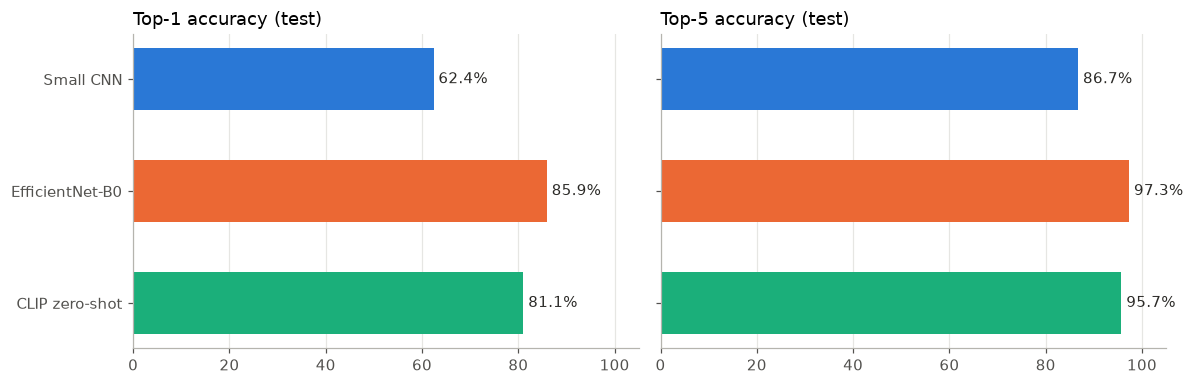

In [15]:
# Accuracy per model: top-1 and top-5 side by side, values written on the bars
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, col, title in zip(axes, ["top1_acc", "top5_acc"], ["Top-1 accuracy (test)", "Top-5 accuracy (test)"]):
    values = metrics[col].to_numpy() * 100
    bars = ax.barh(metrics.index, values, color=SERIES[:len(values)], height=0.55)
    for bar, v in zip(bars, values):
        ax.text(v + 1, bar.get_y() + bar.get_height() / 2, f"{v:.1f}%", va="center", color="#2b2a27", fontsize=10)
    ax.set_xlim(0, 105); ax.set_title(title, loc="left"); ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
plt.tight_layout(); plt.savefig(RESULTS_DIR / "accuracy_comparison.png", bbox_inches="tight"); plt.show()

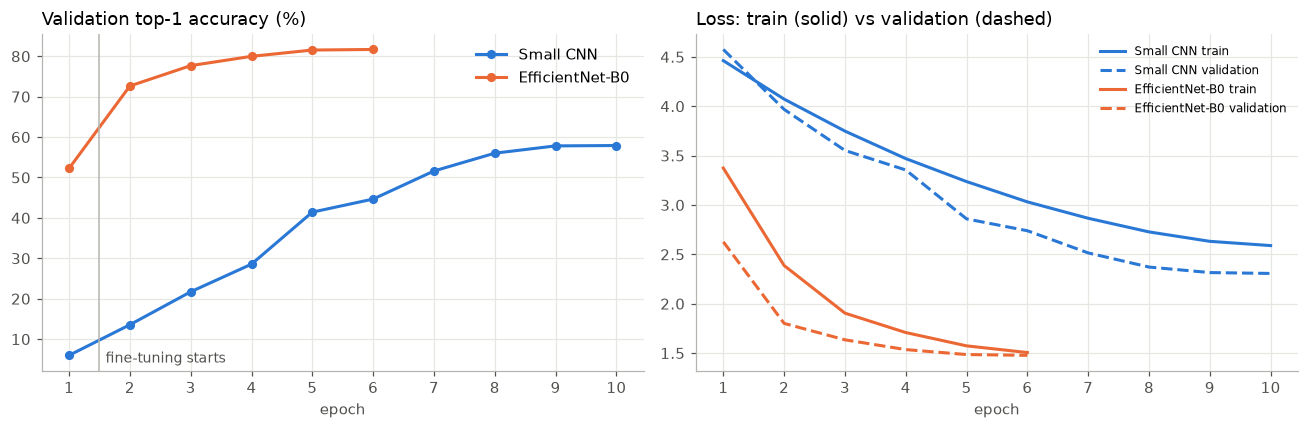

In [16]:
# Learning curves: validation top-1 per epoch, and train vs validation loss (overfitting check)
hist = pd.DataFrame(HISTORY)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for color, (name, h) in zip(SERIES, hist.groupby("model", sort=False)):
    axes[0].plot(h.epoch, h.val_top1 * 100, marker="o", markersize=5, lw=2, color=color, label=name)
    axes[1].plot(h.epoch, h.train_loss, lw=2, color=color, label=f"{name} train")
    axes[1].plot(h.epoch, h.val_loss, lw=2, ls="--", color=color, label=f"{name} validation")
head_end = hist[(hist.model == "EfficientNet-B0") & (hist.stage == "head")].epoch.max()
if pd.notna(head_end):
    axes[0].axvline(head_end + 0.5, color="#b5b4ae", lw=1)
    axes[0].annotate("fine-tuning starts", (head_end + 0.6, axes[0].get_ylim()[0] + 2), color="#52514e", fontsize=9)
from matplotlib.ticker import MaxNLocator
for ax, title in zip(axes, ["Validation top-1 accuracy (%)", "Loss: train (solid) vs validation (dashed)"]):
    ax.set_title(title, loc="left"); ax.set_xlabel("epoch"); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend(frameon=False); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "learning_curves.png", bbox_inches="tight"); plt.show()

### Which dishes get confused? (best model)

The confusion matrix has one row per true dish and one column per predicted dish; a perfect model only has the
diagonal. With 101 dishes the full matrix is large, so the table below lists the pairs that are mixed up most often.

,true dish,predicted as,photos,share of true dish
0,Steak,Filet mignon,37,15%
1,Filet mignon,Steak,29,12%
2,Pork chop,Filet mignon,24,10%
3,Steak,Prime rib,23,9%
4,Chocolate cake,Chocolate mousse,23,9%
5,Chocolate mousse,Chocolate cake,21,8%
6,Tuna tartare,Beef tartare,20,8%
7,Prime rib,Steak,19,8%
8,Ramen,Pho,18,7%
9,Bread pudding,Apple pie,17,7%


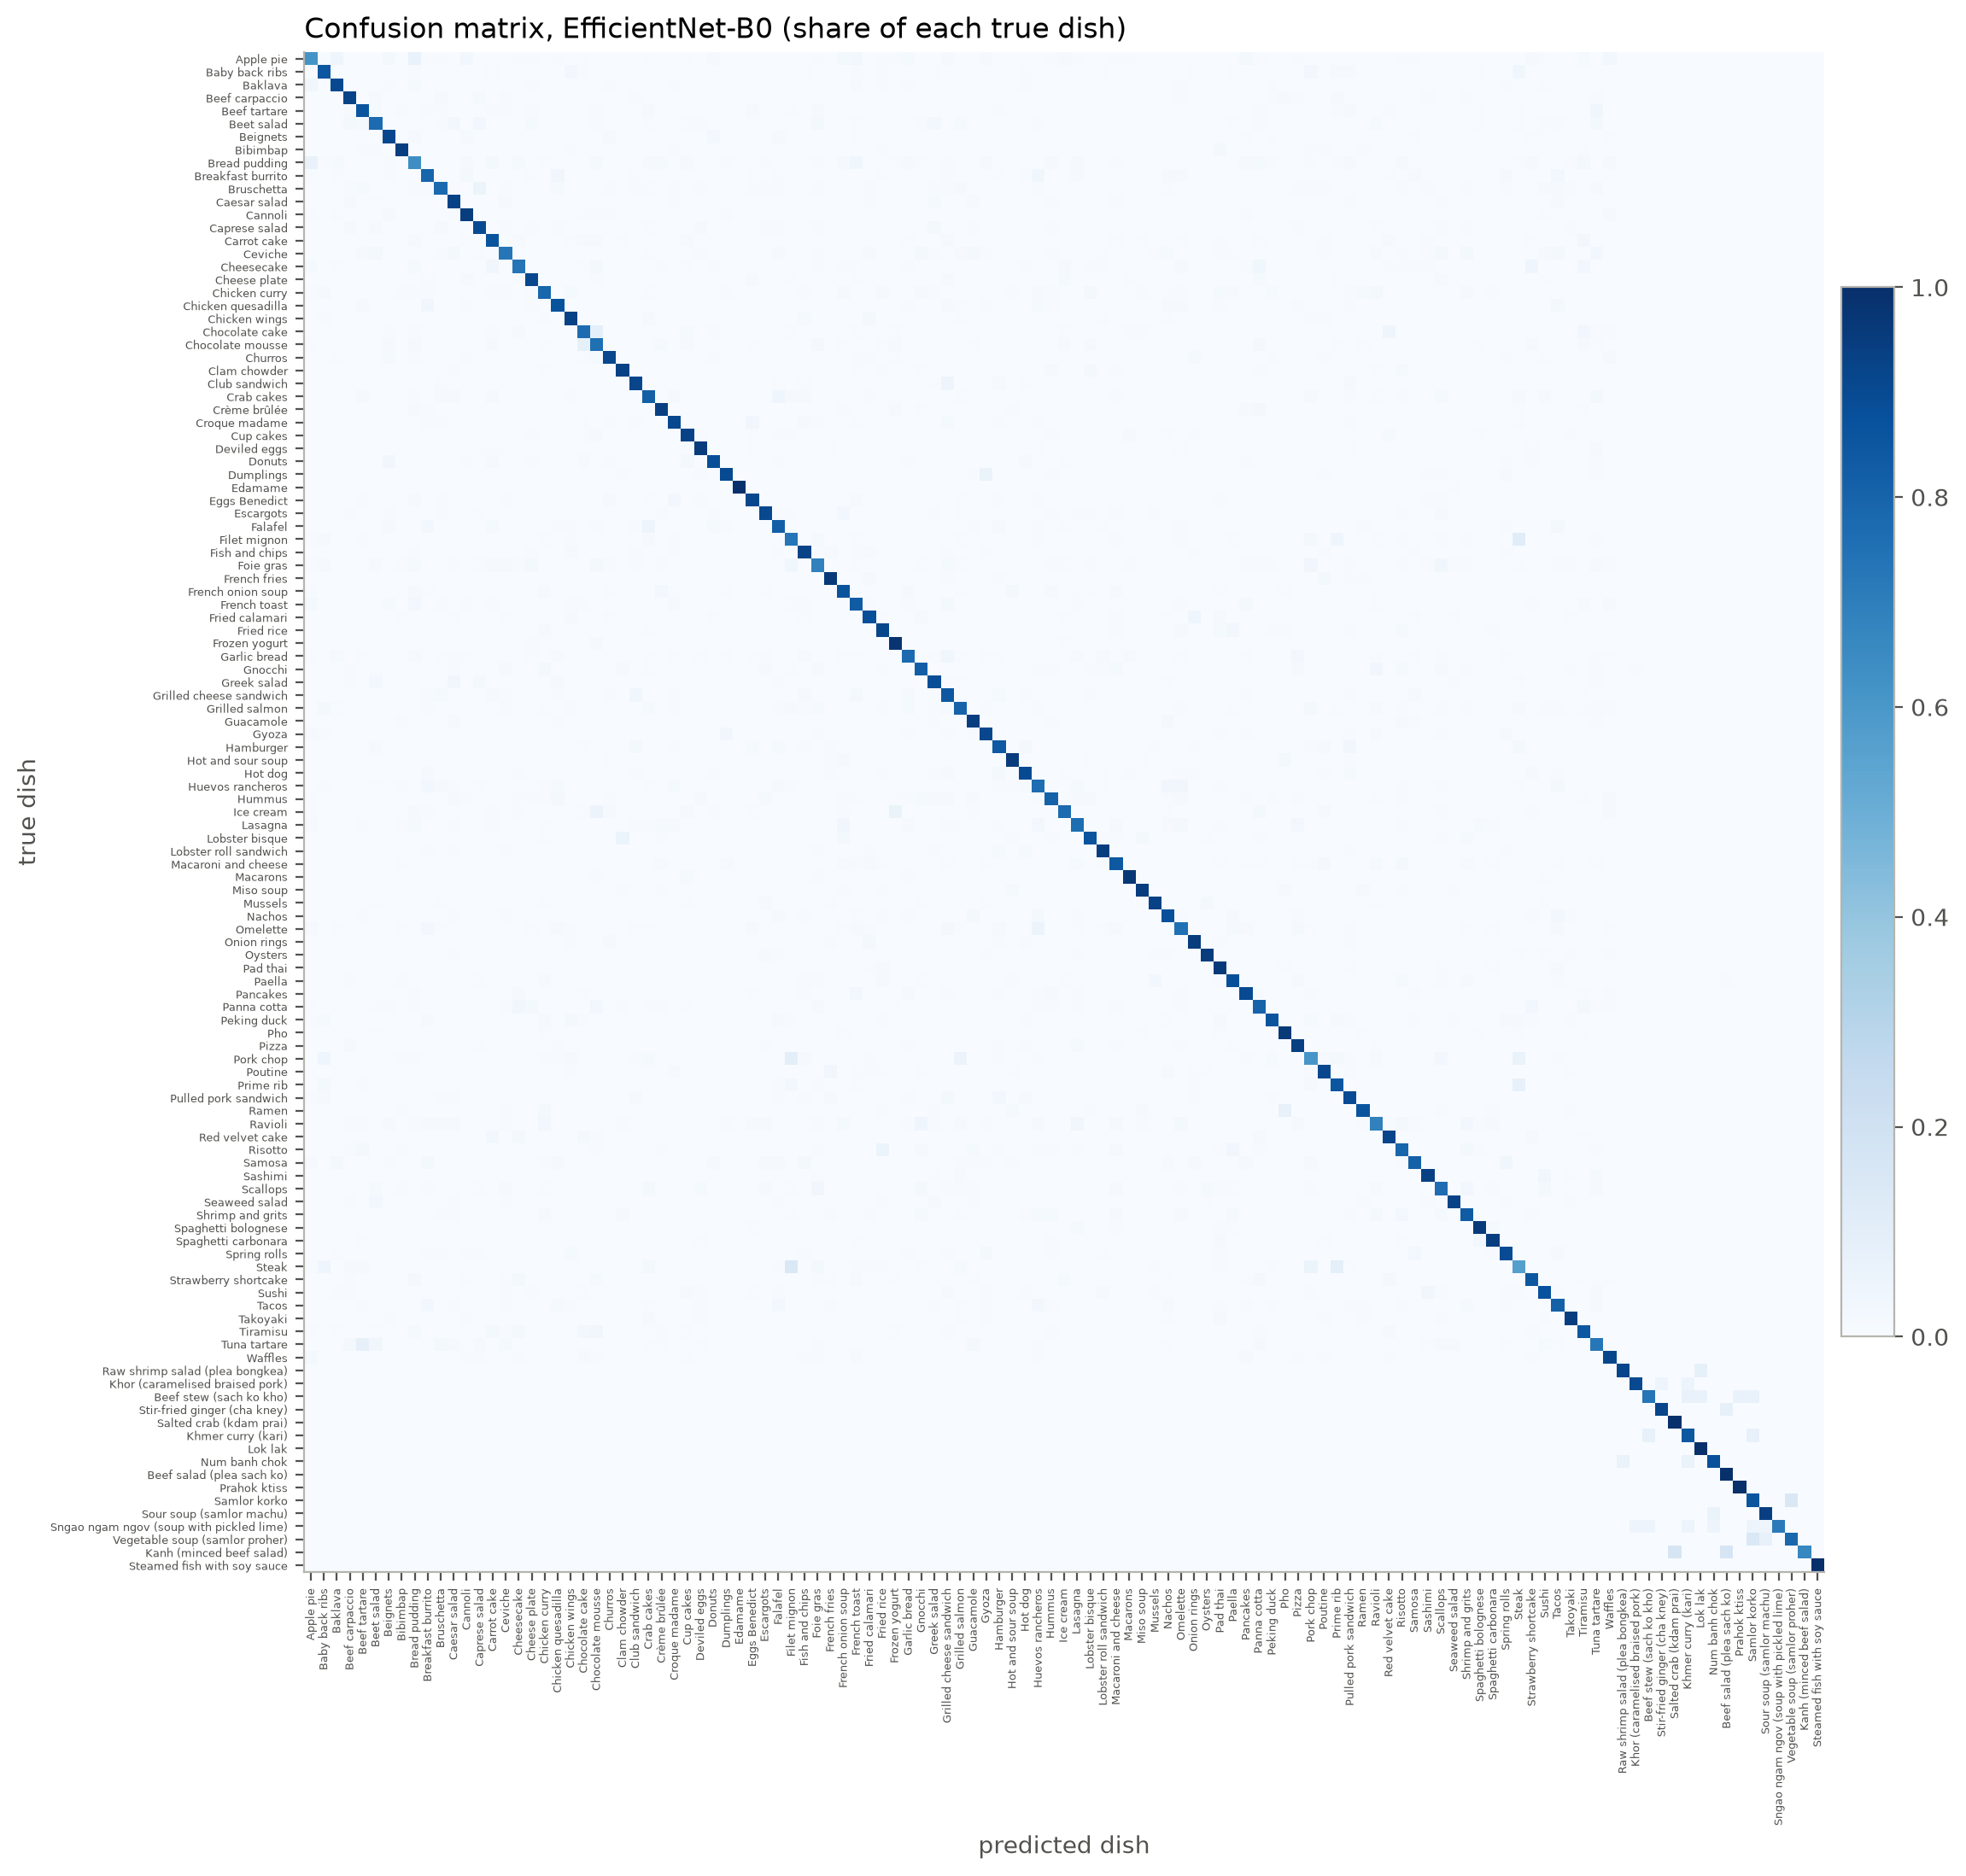

In [17]:
BEST = metrics["top1_acc"].idxmax()
pred_best = PROBS[BEST].argmax(1)
cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
np.add.at(cm, (y_true, pred_best), 1)
cm_rate = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(12, 11))
im = ax.imshow(cm_rate, cmap="Blues", vmin=0, vmax=1)
ticks = np.arange(NUM_CLASSES)
ax.set_xticks(ticks, [display_name(c) for c in CLASSES], rotation=90, fontsize=4.5)
ax.set_yticks(ticks, [display_name(c) for c in CLASSES], fontsize=4.5)
ax.grid(False); ax.set_xlabel("predicted dish"); ax.set_ylabel("true dish")
ax.set_title(f"Confusion matrix, {BEST} (share of each true dish)", loc="left")
fig.colorbar(im, fraction=0.03, pad=0.01)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "confusion_matrix.png", bbox_inches="tight", dpi=200); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = [(off[i, j], i, j) for i, j in zip(*np.nonzero(off))]
confused = pd.DataFrame([{"true dish": display_name(CLASSES[i]), "predicted as": display_name(CLASSES[j]),
                          "photos": n, "share of true dish": f"{cm_rate[i, j]:.0%}"}
                         for n, i, j in sorted(pairs, reverse=True)[:15]])
confused.to_csv(RESULTS_DIR / "most_confused_pairs.csv", index=False)
confused

,Small CNN,EfficientNet-B0,CLIP zero-shot
Raw shrimp salad (plea bongkea) (12),75%,92%,67%
Khor (caramelised braised pork) (20),70%,90%,15%
Beef stew (sach ko kho) (15),40%,73%,60%
Stir-fried ginger (cha kney) (12),100%,92%,50%
Salted crab (kdam prai) (19),84%,100%,11%
Khmer curry (kari) (13),100%,85%,62%
Lok lak (16),81%,100%,0%
Num banh chok (16),81%,88%,19%
Beef salad (plea sach ko) (14),64%,100%,50%
Prahok ktiss (15),80%,100%,0%


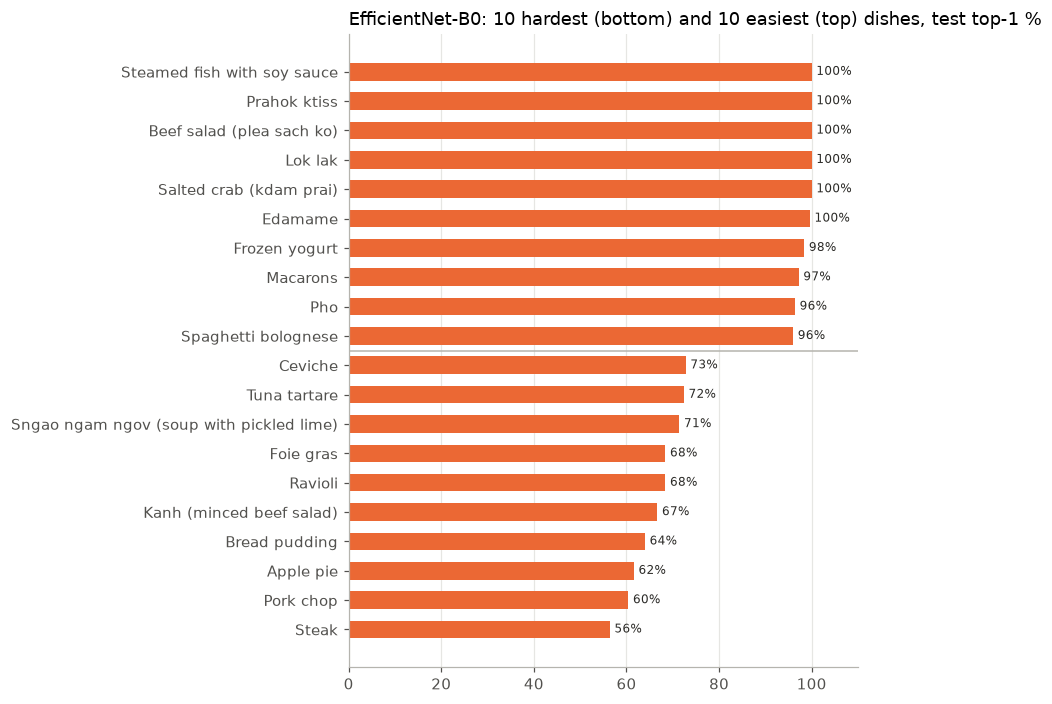

In [18]:
# Per-dish accuracy for all three models; easiest and hardest dishes for the best model
per_dish = pd.DataFrame({name: [(p.argmax(1)[y_true == c] == c).mean() if (y_true == c).any() else np.nan
                                for c in range(NUM_CLASSES)] for name, p in PROBS.items()},
                        index=[display_name(c) for c in CLASSES])
per_dish.to_csv(RESULTS_DIR / "per_dish_accuracy.csv")
if IS_KHMER.any():                              # the Khmer dishes, one row each (test photos per dish in brackets)
    kh = per_dish[IS_KHMER].copy()
    kh.index = [f"{n} ({int((y_true == c).sum())})" for n, c in zip(kh.index, np.where(IS_KHMER)[0])]
    kh.to_csv(RESULTS_DIR / "khmer_dish_accuracy.csv")
    display(kh.style.format("{:.0%}").set_caption("Khmer dishes: test top-1 per model (test photos per dish)"))

ranked = per_dish[BEST].sort_values()
show = pd.concat([ranked.head(10), ranked.tail(10)]) if len(ranked) > 20 else ranked
fig, ax = plt.subplots(figsize=(8, 6.5))
bars = ax.barh(show.index, show.to_numpy() * 100, color=SERIES[list(MODELS).index(BEST)], height=0.6)
for bar, v in zip(bars, show.to_numpy() * 100):
    ax.text(v + 1, bar.get_y() + bar.get_height() / 2, f"{v:.0f}%", va="center", fontsize=8, color="#2b2a27")
if len(ranked) > 20:
    ax.axhline(9.5, color="#b5b4ae", lw=1)
ax.set_xlim(0, 110); ax.grid(axis="y", visible=False)
ax.set_title(f"{BEST}: 10 hardest (bottom) and 10 easiest (top) dishes, test top-1 %", loc="left")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "hardest_easiest_dishes.png", bbox_inches="tight"); plt.show()

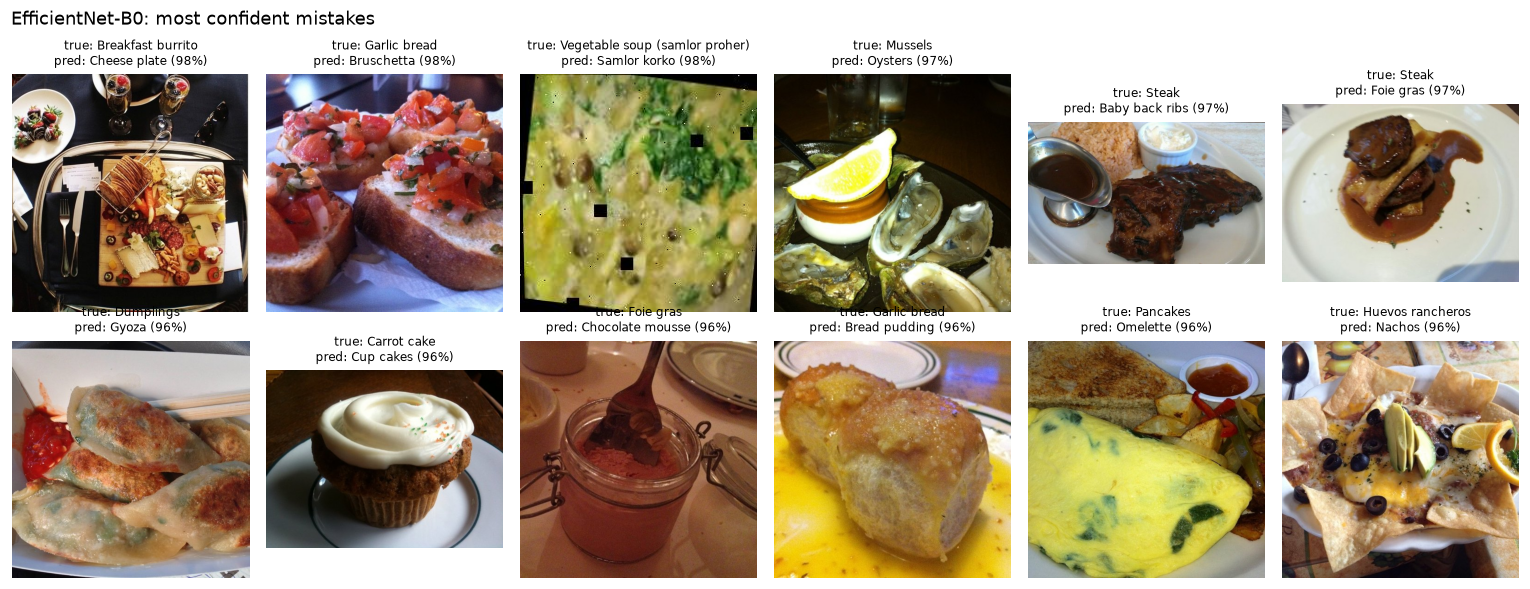

In [19]:
# Error analysis: the best model's most confident mistakes
conf = PROBS[BEST].max(1)
wrong = np.where(pred_best != y_true)[0]
worst = wrong[np.argsort(-conf[wrong])][:12]
fig, axes = plt.subplots(2, 6, figsize=(14, 5.5))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, worst):
    ax.imshow(Image.open(test_df.path[i]).convert("RGB"))
    ax.set_title(f"true: {display_name(CLASSES[y_true[i]])}\npred: {display_name(CLASSES[pred_best[i]])} ({conf[i]:.0%})",
                 fontsize=8)
fig.suptitle(f"{BEST}: most confident mistakes", x=0.01, ha="left")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "confident_mistakes.png", bbox_inches="tight"); plt.show()

## 7. Try it on any photo

`classify_photo(path)` returns the 5 most likely dishes with their probability. This is exactly what the app does
when someone uploads a photo.

In [20]:
APP_TRANSFORM = eval_transform(CONFIG["eff_img"])


@torch.no_grad()
def classify_photo(path, k=5, model=None):
    model = (model or eff).eval()
    x = APP_TRANSFORM(Image.open(path).convert("RGB")).unsqueeze(0).to(DEVICE)
    probs = model(x).float().softmax(dim=1)[0].cpu()
    p, idx = probs.topk(min(k, NUM_CLASSES))
    return [(display_name(CLASSES[i]), round(float(q), 3)) for q, i in zip(p, idx)]


sample = test_df.sample(1, random_state=7).iloc[0]
print("true dish:", display_name(CLASSES[sample.label]))
classify_photo(sample.path)

true dish: Cup cakes


[('Cup cakes', 0.947),
 ('Red velvet cake', 0.016),
 ('Carrot cake', 0.002),
 ('Chocolate cake', 0.002),
 ('Chocolate mousse', 0.001)]

## 8. Export the model for the app

The search app (`backend/food_search/dishes.py`, generated by `food_search.ipynb`) loads these two files:

* `models/food101_efficientnet_b0.pt`: the weights + the settings needed to prepare a photo the same way.
* `models/food101_classes.json`: the 117 dish ids and display names (the ids match `data/recipes.csv`).

In [21]:
best_eff = metrics.loc["EfficientNet-B0"]
torch.save({"arch": "efficientnet_b0", "state_dict": {k: v.cpu() for k, v in eff.state_dict().items()},
            "classes": CLASSES, "img_size": CONFIG["eff_img"], "resize": int(CONFIG["eff_img"] * 1.14),
            "mean": MEAN, "std": STD, "quick_run": QUICK_RUN, "run": RUN_KIND, "config": CONFIG,
            "test_top1": float(best_eff.top1_acc), "test_top5": float(best_eff.top5_acc),
            "test_top1_food101": float(best_eff.top1_food101), "test_top1_khmer": float(best_eff.top1_khmer),
            "trained": time.strftime("%Y-%m-%d")}, MODELS_DIR / "food101_efficientnet_b0.pt")
(MODELS_DIR / "food101_classes.json").write_text(
    json.dumps([{"id": c, "name": display_name(c), **{k: v for k, v in INFO.items() if k in ("name_kh", "search") and v}}
                for c, INFO in ((c, next((k for k in KHMER_INFO if k["id"] == c), {})) for c in CLASSES)],
               indent=1, ensure_ascii=False), encoding="utf-8")
print("saved:", *(f"  {p.relative_to(ROOT)}  {p.stat().st_size / 1e6:.1f} MB" for p in sorted(MODELS_DIR.glob("food101_*"))), sep="\n")

if IN_KAGGLE or IN_COLAB:   # one zip to download and unzip into the project folder
    archive = shutil.make_archive(str(ROOT / "food_classification_outputs"), "zip", ROOT, "models")
    shutil.make_archive(str(ROOT / "_results"), "zip", ROOT, "results")
    import zipfile
    with zipfile.ZipFile(archive, "a") as z, zipfile.ZipFile(ROOT / "_results.zip") as r:
        for item in r.namelist():
            z.writestr(item, r.read(item))
    (ROOT / "_results.zip").unlink()
    print("download:", archive)

saved:
  models/food101_classes.json  0.0 MB
  models/food101_efficientnet_b0.pt  16.9 MB
  models/food101_small_cnn.pt  13.8 MB


## 9. Learning from user corrections (no retraining)

A trained model is fixed: the same photo always gets the same answer. The app therefore learns from its users in two ways:

1. **At once, with a memory (nearest neighbour).** When a guess is wrong and the user says what it really is (a tap under *"Not it?"*, or *"no, it's amok"*), the app saves the photo's **fingerprint** (the 1,280 numbers EfficientNet-B0 computes just before its last layer, as a unit vector) with the right dish. For each new photo it first looks for a saved fingerprint that is close enough (cosine similarity):
   * the person's **own** correction counts from `OWN_PHOTO_AT` (it only changes that person's answers);
   * **someone else's** correction only for a near-identical photo, from `OTHERS_PHOTO_AT`, so a wrong (or joke) correction can hardly change other people's answers.
2. **Later, by retraining (human in the loop).** The corrected photos are saved in `data/feedback/photos/<dish>/` and section 1 adds them to the training set (`use_feedback`) the next time this notebook runs. That is how the model learns a dish *in general*. Check the photos first with `python scrapers/feedback_review.py` (remove wrong ones with `--remove`).

The app does this in `backend/food_search/dishes.py` (`recognise`, `learn`). This section measures the cut-offs and simulates users correcting the model on the test set. Only the exported model (`models/food101_efficientnet_b0.pt`) is needed, so the section also runs on its own after sections 0–1.

In [ ]:
import io, zlib

# The model the app uses (exported in section 8)
ckpt = torch.load(MODELS_DIR / "food101_efficientnet_b0.pt", map_location="cpu", weights_only=True)
app_net = torchvision.models.efficientnet_b0(weights=None)
app_net.classifier[1] = nn.Linear(app_net.classifier[1].in_features, len(ckpt["classes"]))
app_net.load_state_dict(ckpt["state_dict"])
app_net = app_net.eval().to(DEVICE)
assert list(ckpt["classes"]) == CLASSES
APP_TF = eval_transform(ckpt["img_size"])


class ResentPhotos(FoodDataset):
    # The same photos as a user would send them again: smaller (50-100%), cut a little at the edges (0-8%),
    # saved again as JPEG (quality 55-85), as chat apps do. Always the same copy for the same photo.
    def __getitem__(self, i):
        rng = random.Random(zlib.crc32(self.paths[i].encode()))
        img = Image.open(self.paths[i]).convert("RGB")
        s = rng.uniform(0.5, 1.0)
        img = img.resize((max(1, int(img.width * s)), max(1, int(img.height * s))))
        c = rng.uniform(0, 0.08)
        img = img.crop((int(img.width * c), int(img.height * c), int(img.width * (1 - c)), int(img.height * (1 - c))))
        buf = io.BytesIO()
        img.save(buf, "JPEG", quality=rng.randint(55, 85))
        return self.transform(Image.open(io.BytesIO(buf.getvalue())).convert("RGB")), self.labels[i]


@torch.no_grad()
def fingerprints(dataset):
    # (unit fingerprints, class probabilities) for every photo, as in dishes.py
    feats, probs = [], []
    for x, _ in DataLoader(dataset, batch_size=CONFIG["batch_size"]):
        f = app_net.avgpool(app_net.features(x.to(DEVICE))).flatten(1).float()
        probs.append(app_net.classifier(f).softmax(dim=1).cpu())
        feats.append(nn.functional.normalize(f, dim=1).cpu())
    return torch.cat(feats).numpy(), torch.cat(probs).numpy()


start = time.time()
F_test, P_test = fingerprints(FoodDataset(test_df, APP_TF))
F_resent, P_resent = fingerprints(ResentPhotos(test_df, APP_TF))
y_test = test_df["label"].to_numpy()
pred_test, pred_resent = P_test.argmax(1), P_resent.argmax(1)
print(f"{len(test_df):,} test photos + their re-sent copies in {time.time() - start:.0f} s | top-1: original "
      f"{(pred_test == y_test).mean():.1%}, re-sent {(pred_resent == y_test).mean():.1%}")

25,483 test photos + their re-sent copies in 131 s | top-1: original 85.9%, re-sent 81.7%


7,920,886 pairs of photos of different dishes, 77,114 pairs of the same dish


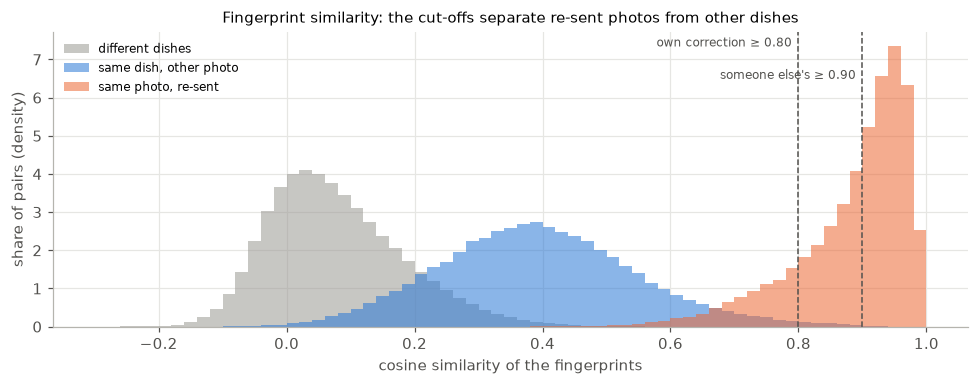

,re-sent copy found,"same dish, other photo",different dish (false match),false matches
cut-off,,,,
0.500000,99.79%,23.07%,0.06%,4977
0.550000,99.53%,14.80%,0.02%,1499
0.600000,98.91%,9.20%,0.01%,430
0.650000,97.65%,5.49%,0.00%,105
0.700000,95.03%,3.17%,0.00%,20
0.750000,90.46%,1.70%,0.00%,1
0.800000,83.84%,0.84%,0.00%,0
0.850000,73.51%,0.31%,0.00%,0
0.900000,56.04%,0.05%,0.00%,0


In [ ]:
# How close are the fingerprints of (a) a photo and its re-sent copy, (b) two photos of the same dish,
# (c) two photos of different dishes? The cut-offs must catch (a) and almost never (c).
rng = np.random.default_rng(SEED)
same_photo = (F_test * F_resent).sum(1)
pick = rng.choice(len(test_df), size=min(4000, len(test_df)), replace=False)
S = F_test[pick] @ F_test[pick].T
labels = y_test[pick]
upper = np.triu(np.ones_like(S, dtype=bool), k=1)
same_dish = S[upper & (labels[:, None] == labels[None, :])]
other_dish = S[upper & (labels[:, None] != labels[None, :])]

OWN_PHOTO_AT, OTHERS_PHOTO_AT = 0.80, 0.90       # the values in dishes.py
rows = []
for th in (0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90):
    rows.append({"cut-off": th, "re-sent copy found": (same_photo >= th).mean(),
                 "same dish, other photo": (same_dish >= th).mean(), "different dish (false match)": (other_dish >= th).mean(),
                 "false matches": int((other_dish >= th).sum())})
cutoffs = pd.DataFrame(rows).set_index("cut-off")
cutoffs.to_csv(RESULTS_DIR / "feedback_cutoffs.csv")
print(f"{len(other_dish):,} pairs of photos of different dishes, {len(same_dish):,} pairs of the same dish")

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.linspace(-0.3, 1, 66)
for values, label, color in ((other_dish, "different dishes", "#9a9993"), (same_dish, "same dish, other photo", SERIES[0]),
                             (same_photo, "same photo, re-sent", SERIES[1])):
    ax.hist(values, bins=bins, density=True, alpha=0.55, color=color, label=label)
top = ax.get_ylim()[1]
for th, name, height in ((OWN_PHOTO_AT, "own correction ≥ 0.80", 0.95), (OTHERS_PHOTO_AT, "someone else's ≥ 0.90", 0.84)):
    ax.axvline(th, color="#52514e", lw=1, ls="--")
    ax.text(th - 0.01, top * height, name, fontsize=8, color="#52514e", ha="right")
ax.set_xlabel("cosine similarity of the fingerprints"); ax.set_ylabel("share of pairs (density)")
ax.set_title("Fingerprint similarity: the cut-offs separate re-sent photos from other dishes", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "feedback_similarity.png", dpi=150); plt.show()
cutoffs.style.format({c: "{:.2%}" for c in cutoffs.columns if c != "false matches"})

In [ ]:
def with_memory(queries, model_pred, mem_f, mem_label, mem_user, query_user, own_at=OWN_PHOTO_AT,
                others_at=OTHERS_PHOTO_AT, similar_at=None, min_users=2):
    # The rule of dishes.py (_recall): the corrections' answer for each query photo, else the model's.
    # similar_at: the wider rule that was tested and dropped (similar photos, if min_users people agree).
    sims = queries @ mem_f.T
    out, used = model_pred.copy(), np.zeros(len(queries), dtype=bool)
    for i in np.flatnonzero(sims.max(1) >= min(own_at, others_at, similar_at or 1)):
        row = sims[i]
        own = np.flatnonzero((mem_user == query_user[i]) & (row >= own_at))
        if len(own):
            out[i], used[i] = mem_label[own[row[own].argmax()]], True
            continue
        for cut, need in ((others_at, 1), (similar_at, min_users)):
            hits = np.flatnonzero(row >= cut) if cut else []
            if len(hits) == 0:
                continue
            votes = {}
            for j in hits:
                users, best = votes.get(mem_label[j], (set(), 0.0))
                votes[mem_label[j]] = (users | {mem_user[j]}, max(best, row[j]))
            dish, (users, _) = max(votes.items(), key=lambda kv: (len(kv[1][0]), kv[1][1]))
            if len(users) >= need:
                out[i], used[i] = dish, True
                break
    return out, used


# Half of the test photos are sent by users (A); each wrong guess is corrected by its sender (one person each).
# The other half (B) are new photos from other people: they show what the memory does to everybody else.
order = rng.permutation(len(test_df))
A, B = order[: len(order) // 2], order[len(order) // 2:]
fixes = A[pred_test[A] != y_test[A]]
user_of = np.full(len(test_df), -1)                    # who sent a photo (-1: a person who corrected nothing)
user_of[fixes] = np.arange(len(fixes))
mem = (F_test[fixes], y_test[fixes], user_of[fixes])   # fingerprint, right dish, who corrected

# Joke / mistaken corrections: photos the model got RIGHT, "corrected" to a random wrong dish by their senders
jokes = rng.choice(A[pred_test[A] == y_test[A]], size=len(fixes) // 2, replace=False)
user_of[jokes] = len(fixes) + np.arange(len(jokes))
joke_labels = (y_test[jokes] + rng.integers(1, NUM_CLASSES, size=len(jokes))) % NUM_CLASSES
mem_jokes = (np.concatenate([mem[0], F_test[jokes]]), np.concatenate([mem[1], joke_labels]),
             np.concatenate([mem[2], user_of[jokes]]))
someone_else = np.full(len(test_df), -1)


def score(name, idx, feats, pred, memory, users, **kw):
    after, used = with_memory(feats[idx], pred[idx], *memory, users[idx], **kw)
    truth = y_test[idx]
    return {"case": name, "photos": len(idx), "top-1 before": (pred[idx] == truth).mean(), "top-1 after": (after == truth).mean(),
            "fixed": int(((pred[idx] != truth) & (after == truth)).sum()),
            "broken": int(((pred[idx] == truth) & (after != truth)).sum()), "answered from memory": int(used.sum())}


sim_rows = [
    score("corrected photo, sent again by the same person", fixes, F_resent, pred_resent, mem, user_of),
    score("corrected photo, sent again by someone else", fixes, F_resent, pred_resent, mem, someone_else),
    score("other people's new photos (B)", B, F_test, pred_test, mem, user_of),
    score("other people's new photos (B), with joke corrections", B, F_test, pred_test, mem_jokes, user_of),
    score("dropped rule: + similar photos if 2 people agree (≥ 0.60), B", B, F_test, pred_test, mem, user_of,
          similar_at=0.60),
]
memory_results = pd.DataFrame(sim_rows).set_index("case")
memory_results.to_csv(RESULTS_DIR / "feedback_memory.csv")
print(f"memory: {len(fixes):,} corrections of wrong guesses in half A (+ {len(jokes):,} joke corrections in the joke case)")
memory_results.style.format({"top-1 before": "{:.1%}", "top-1 after": "{:.1%}"})

memory: 1,807 corrections of wrong guesses in half A (+ 903 joke corrections in the joke case)


,photos,top-1 before,top-1 after,fixed,broken,answered from memory
case,,,,,,
"corrected photo, sent again by the same person",1807,14.5%,83.3%,1244,0,1464
"corrected photo, sent again by someone else",1807,14.5%,58.8%,800,0,937
other people's new photos (B),12742,86.0%,86.1%,2,0,2
"other people's new photos (B), with joke corrections",12742,86.0%,85.7%,2,40,42
"dropped rule: + similar photos if 2 people agree (≥ 0.60), B",12742,86.0%,83.6%,41,354,480


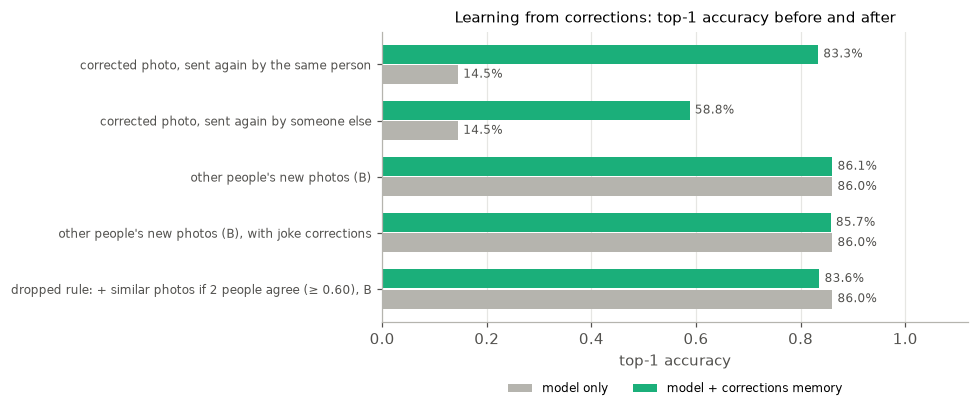

In [ ]:
# Before vs after, per case
fig, ax = plt.subplots(figsize=(9, 3.9))
cases = memory_results.index.tolist()
y = np.arange(len(cases))
ax.barh(y + 0.18, memory_results["top-1 before"], height=0.34, color="#b5b4ae", label="model only")
ax.barh(y - 0.18, memory_results["top-1 after"], height=0.34, color=SERIES[2], label="model + corrections memory")
for i, (b, a) in enumerate(zip(memory_results["top-1 before"], memory_results["top-1 after"])):
    ax.text(b + 0.01, i + 0.18, f"{b:.1%}", va="center", fontsize=8, color="#52514e")
    ax.text(a + 0.01, i - 0.18, f"{a:.1%}", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, cases, fontsize=8); ax.invert_yaxis(); ax.set_xlim(0, 1.12); ax.set_xlabel("top-1 accuracy")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
ax.grid(axis="y", visible=False)
ax.set_title("Learning from corrections: top-1 accuracy before and after", fontsize=10)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "feedback_memory.png", dpi=150); plt.show()

## 10. Summary (run of 7 Nov 2026, Apple M3 Pro GPU)

All 101 Food-101 dishes + 16 Khmer dishes (117 classes). Mac settings: all photos, CNN 10 epochs, EfficientNet 1 + 5 epochs
(an NVIDIA run uses 15 and 2 + 6 epochs). Test set: 25,250 Food-101 photos + 233 Khmer photos, never seen in training.

| Model | Top-1 (all) | Top-5 | Food-101 top-1 | Khmer top-1 | Macro F1 | Parameters | Training |
|---|---|---|---|---|---|---|---|
| Small CNN (from scratch) | 62.4% | 86.7% | 62.3% | 75.5% | 0.630 | 3.4 M | 37 min |
| **EfficientNet-B0 (transfer learning)** | **85.9%** | **97.3%** | **85.9%** | **88.8%** | **0.861** | 4.2 M | 64 min |
| CLIP zero-shot (no training) | 81.1% | 95.7% | 81.5% | 30.0% | 0.734 | 87.8 M (image encoder) | none |

**What the numbers say**

* **Transfer learning wins clearly:** EfficientNet-B0 beats the CNN trained from scratch by 23.5 points with only
  ~20% more parameters, because it starts from features learned on ImageNet. It is also the fastest of the
  pretrained models to run (2.5 ms per photo here).
* **Zero-shot is strong on common dishes and weak on local ones:** CLIP reaches 81.5% on Food-101 without seeing a
  single training photo (dishes like pizza and sushi are all over its internet training data), but only 30.0% on the
  Khmer dishes, whose names it barely knows. Fine-tuning on 699 Khmer photos lifts them to 88.8%.
* **Errors are mostly look-alike dishes:** steak ↔ filet mignon ↔ prime rib ↔ pork chop, chocolate cake ↔ chocolate
  mousse, tuna tartare ↔ beef tartare (`most_confused_pairs.csv`). Hardest dishes: steak (56%), pork chop (60%),
  apple pie (62%).
* **Overfitting:** train and validation loss stay close for EfficientNet (1.51 vs 1.48 in the last epoch), so more
  epochs would probably still help; the learning curves have not flattened yet.
* **Learning from corrections (section 9):** a memory of corrected photos' fingerprints (nearest neighbour, no
  retraining) answers a corrected photo sent again by the same person correctly 83.3% of the time (model alone:
  14.5%), and by someone else 58.8%, without changing any other answer (0 of 12,742 other photos made wrong).
  903 joke corrections made 40 other answers wrong (86.0% → 85.7%). A wider rule ("similar photos if 2 people
  agree") was dropped: it made 354 right answers wrong for 41 fixed, because corrected photos are the ambiguous ones.

**Limits (say these in the report)**

* The Khmer test set is small: 233 photos, 6–21 per dish, from two Roboflow datasets whose photos were already resized
  (224×224) and partly augmented. The Khmer numbers are therefore less precise than the Food-101 ones, and probably
  optimistic (photos from the same few sources look alike), which is also why the small CNN scores higher on Khmer
  dishes (75.5%) than on Food-101 (62.3%).
* The Khmer dish names (khfood classes 00–13 are only numbered) were read from the photos; Kanh is uncertain.
* Fewer epochs than the GPU setting: a Kaggle/Colab run (2 + 6 epochs) would likely add 1–2 points.
* The "sent again" photos in section 9 are simulated (smaller, recompressed, cut a little); a real re-send of the
  same file is usually much closer, so the memory works better on it. Corrections by real users are not part of
  the test set: their effect on the next training run still has to be measured.